# Experiment: Logistic Regression for E-Commerce Purchasing Intention
**Topic:** Imbalanced Binary Classification in Digital Marketing  
**Algorithm:** Logistic Regression with Column Transformers and Class Weight Balancing  
**Dataset:** Online Shoppers Purchasing Intention Dataset (`online_shoppers_intention.csv`)  
**Objective:** Model and predict whether an online browsing session will culminate in a purchase transaction (**Revenue**: True vs. False), eliminate categorical data leakage via pipeline transformers, address class imbalance (~84.5% non-purchasers vs. ~15.5% purchasers), and evaluate Precision-Recall trade-offs.

---

## 1. Problem Statement & Mathematical Formulation

In web analytics, session conversion prediction enables real-time promotional targeting. Given session telemetry $\mathbf{x} \in \mathbb{R}^d$ comprising page visit counts, duration, bounce rates, exit rates, and temporal attributes, we estimate:
$$P(\text{Revenue} = 1 | \mathbf{x}) = \frac{1}{1 + e^{-(\beta_0 + \boldsymbol{\beta}^T \mathbf{x})}}$$

### The Class Imbalance Challenge
Let $N_0$ be the majority class count (sessions without revenue) and $N_1$ be the minority class count (purchasing sessions), with $N_1 \ll N_0$. Standard empirical risk minimization can yield high overall accuracy while failing completely on the minority class:
$$\text{Accuracy}(\text{Predict All 0}) = \frac{N_0}{N_0 + N_1} \approx 84.5\%$$

To incentivize identification of true purchasers, we incorporate cost-sensitive class weights:
$$w_c = \frac{N}{2 \cdot N_c}, \quad c \in \{0, 1\}$$
modifying the weighted log-loss objective:
$$\mathcal{L}_w(\boldsymbol{\beta}) = -\sum_{i=1}^{N} w_{y_i} \Big[ y_i \ln(p_i) + (1 - y_i) \ln(1 - p_i) \Big]$$


In [1]:
# Import dependencies
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Ingestion & Schema Audit

We load the dataset with offline cache fallback and audit attribute types.


In [2]:
DATA_URL = "https://raw.githubusercontent.com/santoshc1/PowerBI-AI-samples/master/Tutorial_AutomatedML/online_shoppers_intention.csv"
LOCAL_PATH = os.path.join("..", "data", "online_shoppers_intention.csv")

if os.path.exists(LOCAL_PATH):
    print(f"Loading cached dataset from: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH)
else:
    print(f"Downloading dataset from: {DATA_URL}")
    df = pd.read_csv(DATA_URL)

df = df.dropna(subset=["Revenue"]).copy()
df["Revenue"] = df["Revenue"].astype(int)

print(f"Dataset Dimensions: {df.shape} (12,330 browsing sessions, 18 features)")
print("\nTarget Class Balance (Revenue):")
target_dist = df["Revenue"].value_counts(normalize=True).mul(100)
print(f"  No Purchase (0): {target_dist[0]:.1f}%")
print(f"  Purchase (1):    {target_dist[1]:.1f}%")

display(df.head())


Loading cached dataset from: ..\data\online_shoppers_intention.csv
Dataset Dimensions: (12330, 18) (12,330 browsing sessions, 18 features)

Target Class Balance (Revenue):
  No Purchase (0): 84.5%
  Purchase (1):    15.5%


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
29,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
30,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
31,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
32,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
33,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


## 3. Exploratory Analysis: Behavioral Signals of Purchase

We examine the impact of behavioral metrics such as `PageValues` (average transaction value of web pages viewed) and `ExitRates` on final purchase status.


C:\Users\DELL\AppData\Local\Temp\ipykernel_17000\175816003.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["No Purchase", "Purchased"])


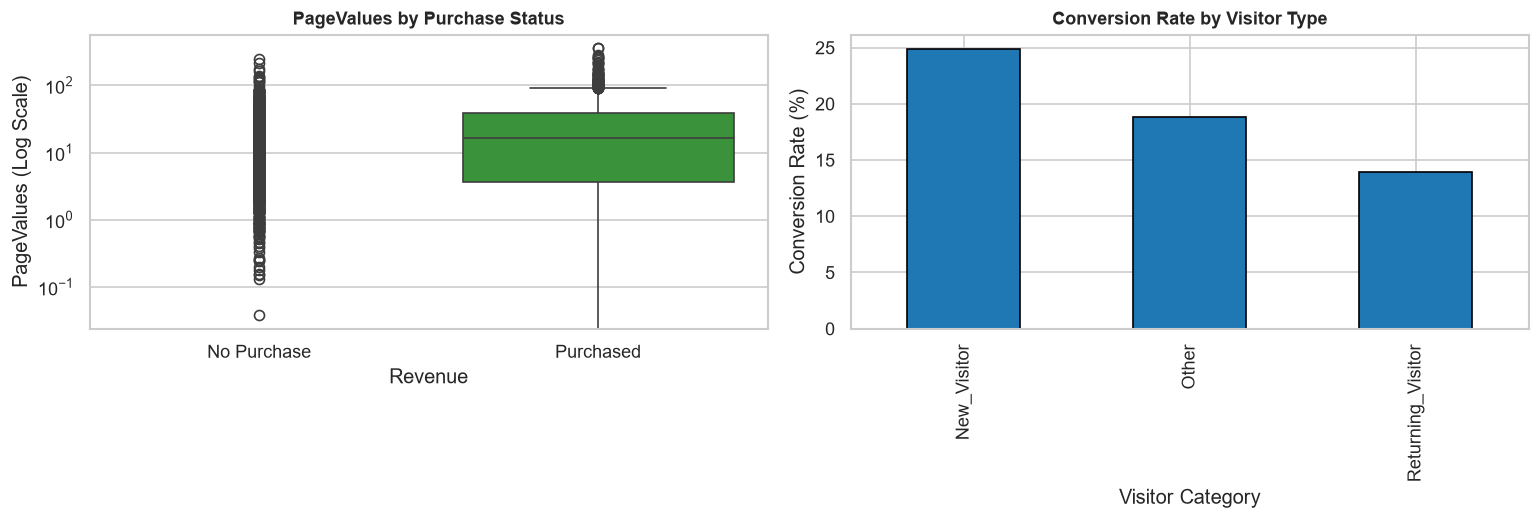

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# PageValues Boxplot
sns.boxplot(data=df, x="Revenue", y="PageValues", hue="Revenue", palette=['#d9534f', '#2ca02c'], legend=False, ax=axes[0])
axes[0].set_title("PageValues by Purchase Status", fontsize=11, fontweight='bold')
axes[0].set_xticklabels(["No Purchase", "Purchased"])
axes[0].set_yscale("log")
axes[0].set_ylabel("PageValues (Log Scale)")

# Conversion Rate by Visitor Type
visitor_conv = df.groupby("VisitorType")["Revenue"].mean().mul(100).sort_values(ascending=False)
visitor_conv.plot(kind="bar", color="#1f77b4", edgecolor="black", ax=axes[1])
axes[1].set_title("Conversion Rate by Visitor Type", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Conversion Rate (%)")
axes[1].set_xlabel("Visitor Category")

plt.tight_layout()
plt.show()


## 4. Pipeline Construction & Leak-Free Train/Test Split

In scikit-learn best practices, one-hot encoding must not be performed on the raw DataFrame before splitting, as that can leak unseen categories or test distributions.
We separate continuous numerical attributes from discrete categorical variables and construct a leak-free `ColumnTransformer`.


In [4]:
numeric_features = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
    "OperatingSystems", "Browser", "Region", "TrafficType"
]

categorical_features = ["Month", "VisitorType", "Weekend"]

X = df[numeric_features + categorical_features]
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Observations: {len(X_train):,}")
print(f"Testing Observations:  {len(X_test):,}")

# Preprocessor: Scale numericals, OneHotEncode categoricals
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), categorical_features)
    ]
)

# Standard Logistic Regression Pipeline
model_standard = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

# Balanced Logistic Regression Pipeline (Cost-Sensitive)
model_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])

model_standard.fit(X_train, y_train)
model_balanced.fit(X_train, y_train)
print("Standard and Balanced Logistic Regression models trained successfully.")


Training Observations: 9,864
Testing Observations:  2,466


Standard and Balanced Logistic Regression models trained successfully.


## 5. Comparative Evaluation: Standard vs. Balanced Models

We evaluate both models on the test set, highlighting how class weighting trades slight precision for a dramatic increase in **Recall** (identifying actual converting customers).


=== Standard Logistic Regression (Default Threshold = 0.50) ===
Accuracy: 88.16% | ROC-AUC: 0.8876
              precision    recall  f1-score   support

 No Purchase       0.89      0.98      0.93      2084
   Purchased       0.75      0.36      0.48       382

    accuracy                           0.88      2466
   macro avg       0.82      0.67      0.71      2466
weighted avg       0.87      0.88      0.86      2466

=== Balanced Logistic Regression (class_weight='balanced') ===
Accuracy: 85.00% | ROC-AUC: 0.8963


              precision    recall  f1-score   support

 No Purchase       0.95      0.87      0.91      2084
   Purchased       0.51      0.75      0.61       382

    accuracy                           0.85      2466
   macro avg       0.73      0.81      0.76      2466
weighted avg       0.88      0.85      0.86      2466



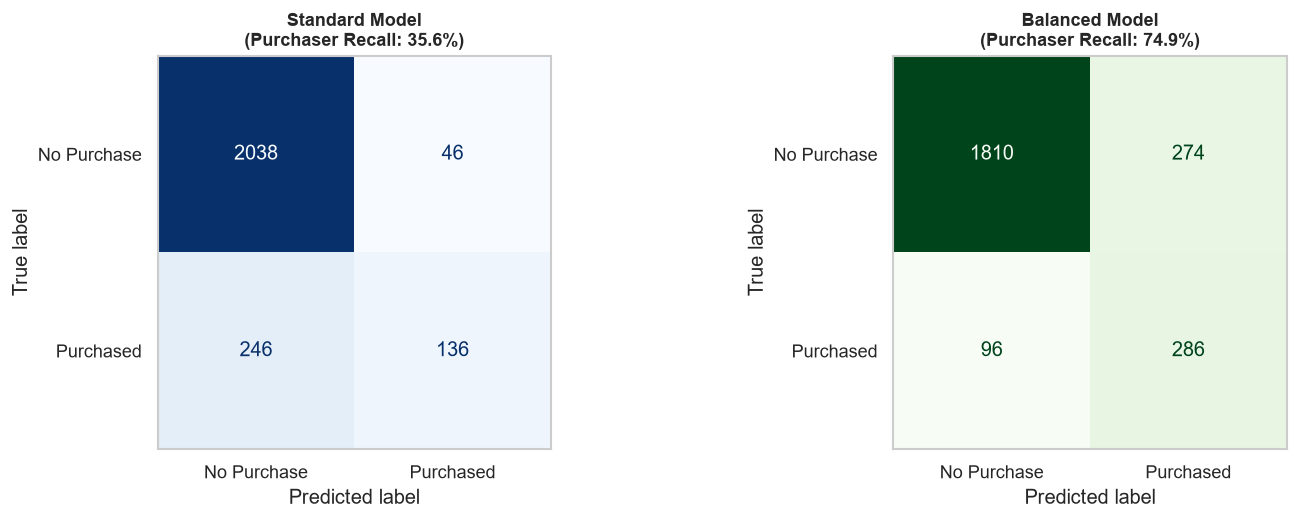

In [5]:
# Standard Model Predictions
y_pred_std = model_standard.predict(X_test)
y_prob_std = model_standard.predict_proba(X_test)[:, 1]

# Balanced Model Predictions
y_pred_bal = model_balanced.predict(X_test)
y_prob_bal = model_balanced.predict_proba(X_test)[:, 1]

print("=== Standard Logistic Regression (Default Threshold = 0.50) ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_std)*100:.2f}% | ROC-AUC: {roc_auc_score(y_test, y_prob_std):.4f}")
print(classification_report(y_test, y_pred_std, target_names=["No Purchase", "Purchased"]))

print("=== Balanced Logistic Regression (class_weight='balanced') ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_bal)*100:.2f}% | ROC-AUC: {roc_auc_score(y_test, y_prob_bal):.4f}")
print(classification_report(y_test, y_pred_bal, target_names=["No Purchase", "Purchased"]))

# Visual Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cm_std = confusion_matrix(y_test, y_pred_std)
ConfusionMatrixDisplay(cm_std, display_labels=["No Purchase", "Purchased"]).plot(
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title(f"Standard Model\n(Purchaser Recall: {cm_std[1,1]/(cm_std[1,0]+cm_std[1,1])*100:.1f}%)", fontsize=11, fontweight='bold')
axes[0].grid(False)

cm_bal = confusion_matrix(y_test, y_pred_bal)
ConfusionMatrixDisplay(cm_bal, display_labels=["No Purchase", "Purchased"]).plot(
    cmap="Greens", ax=axes[1], colorbar=False
)
axes[1].set_title(f"Balanced Model\n(Purchaser Recall: {cm_bal[1,1]/(cm_bal[1,0]+cm_bal[1,1])*100:.1f}%)", fontsize=11, fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()


### Discriminative Evaluation: ROC and Precision-Recall Curves
In imbalanced classification, the **Precision-Recall Curve (PR-AUC / Average Precision)** is the definitive benchmark because it focuses directly on the minority class.


F:\python\Lib\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
F:\python\Lib\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


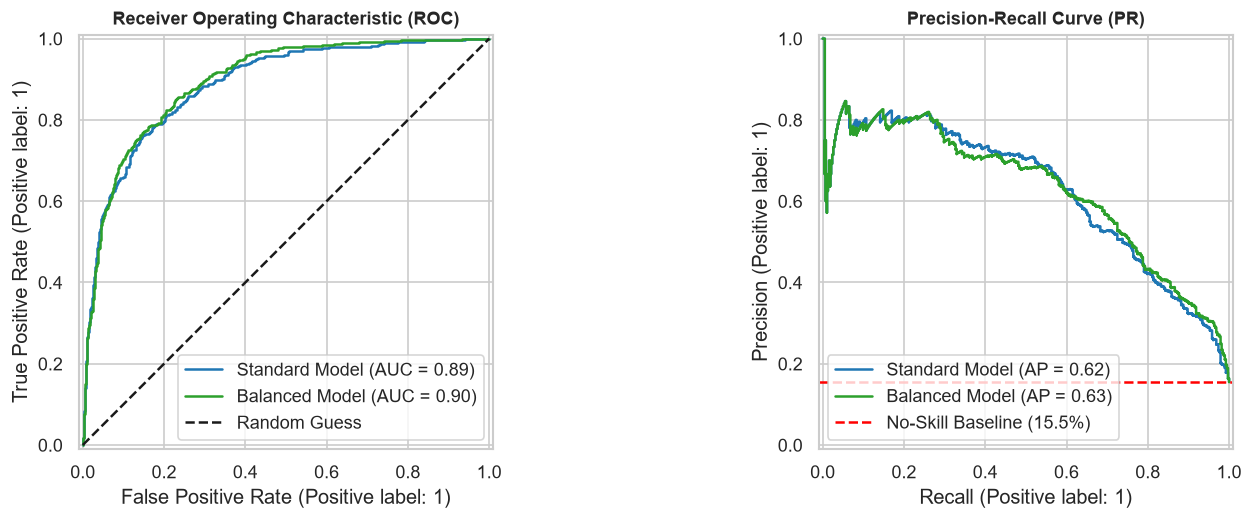

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob_std, ax=axes[0], name="Standard Model", color="#1f77b4")
RocCurveDisplay.from_predictions(y_test, y_prob_bal, ax=axes[0], name="Balanced Model", color="#2ca02c")
axes[0].plot([0, 1], [0, 1], "k--", label="Random Guess")
axes[0].set_title("Receiver Operating Characteristic (ROC)", fontsize=11, fontweight='bold')
axes[0].legend()

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob_std, ax=axes[1], name="Standard Model", color="#1f77b4")
PrecisionRecallDisplay.from_predictions(y_test, y_prob_bal, ax=axes[1], name="Balanced Model", color="#2ca02c")
baseline_pr = y_test.mean()
axes[1].axhline(baseline_pr, color="red", linestyle="--", label=f"No-Skill Baseline ({baseline_pr*100:.1f}%)")
axes[1].set_title("Precision-Recall Curve (PR)", fontsize=11, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


## 6. Top Predictors of Purchasing Conversion

We examine the learned model coefficients to identify the strongest positive and negative behavioral indicators.


Top 10 Influential Features by Absolute Weight:


,Feature,Coefficient
0,PageValues,1.535
1,Month_Feb,-1.310
2,ExitRates,-0.820
3,Month_Nov,0.538
4,Month_May,-0.474
5,Month_Mar,-0.456
6,Month_Dec,-0.440
7,VisitorType_Other,-0.329
8,BounceRates,-0.236
9,VisitorType_Returning_Visitor,-0.234


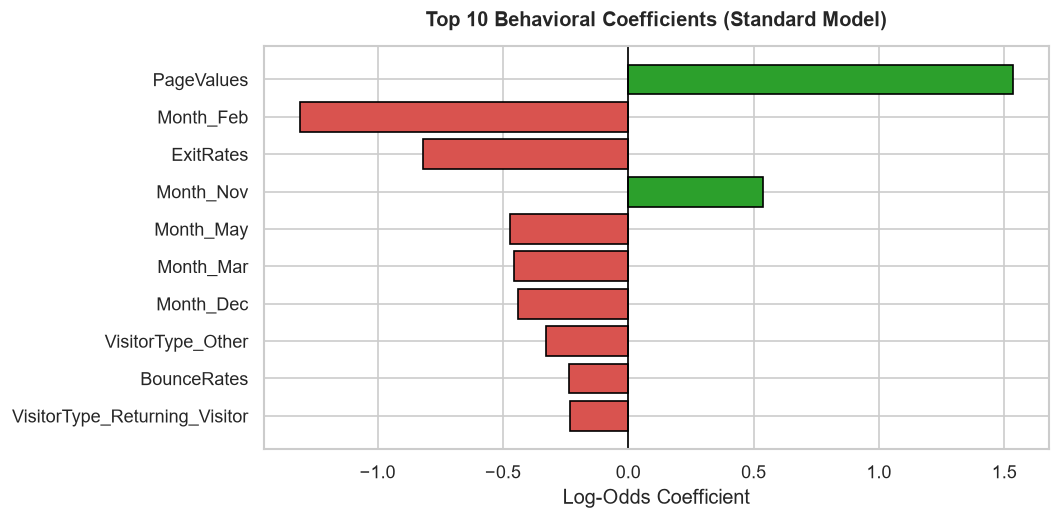

In [7]:
# Extract feature names from fitted pipeline
clf = model_standard.named_steps["classifier"]
num_cols = numeric_features
cat_cols = model_standard.named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(categorical_features)
all_features = list(num_cols) + list(cat_cols)

coef_df = pd.DataFrame({
    'Feature': all_features,
    'Coefficient': clf.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False).head(10).reset_index(drop=True)

print("Top 10 Influential Features by Absolute Weight:")
display(coef_df.round(3))

plt.figure(figsize=(9, 4.5))
colors = ['#2ca02c' if c > 0 else '#d9534f' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black')
plt.axvline(0, color='black', linewidth=1)
plt.title("Top 10 Behavioral Coefficients (Standard Model)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Log-Odds Coefficient")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 7. Predictive Inference on Scenario Browsing Sessions

We simulate conversion probabilities for distinct user sessions:
- **Session 1 (Engaged Buyer):** High `PageValues`, moderate browsing, November shopping event.
- **Session 2 (Casual Browser):** High `BounceRates`, 0 `PageValues`, single page viewed.
- **Session 3 (Researcher):** Multiple product pages, moderate duration, 0 `PageValues`.


In [8]:
scenario_sessions = pd.DataFrame([
    {
        'Administrative': 3, 'Administrative_Duration': 60.0,
        'Informational': 1, 'Informational_Duration': 15.0,
        'ProductRelated': 25, 'ProductRelated_Duration': 850.0,
        'BounceRates': 0.005, 'ExitRates': 0.015, 'PageValues': 45.2, 'SpecialDay': 0.0,
        'OperatingSystems': 2, 'Browser': 2, 'Region': 1, 'TrafficType': 2,
        'Month': 'Nov', 'VisitorType': 'Returning_Visitor', 'Weekend': False
    },
    {
        'Administrative': 0, 'Administrative_Duration': 0.0,
        'Informational': 0, 'Informational_Duration': 0.0,
        'ProductRelated': 1, 'ProductRelated_Duration': 0.0,
        'BounceRates': 0.20, 'ExitRates': 0.20, 'PageValues': 0.0, 'SpecialDay': 0.0,
        'OperatingSystems': 1, 'Browser': 1, 'Region': 1, 'TrafficType': 1,
        'Month': 'May', 'VisitorType': 'Returning_Visitor', 'Weekend': False
    },
    {
        'Administrative': 2, 'Administrative_Duration': 45.0,
        'Informational': 0, 'Informational_Duration': 0.0,
        'ProductRelated': 18, 'ProductRelated_Duration': 520.0,
        'BounceRates': 0.02, 'ExitRates': 0.04, 'PageValues': 0.0, 'SpecialDay': 0.0,
        'OperatingSystems': 2, 'Browser': 2, 'Region': 3, 'TrafficType': 3,
        'Month': 'Dec', 'VisitorType': 'New_Visitor', 'Weekend': True
    }
])

probs_std = model_standard.predict_proba(scenario_sessions)[:, 1]
probs_bal = model_balanced.predict_proba(scenario_sessions)[:, 1]

scenario_sessions['P(Purchase)_Standard'] = (probs_std * 100).round(1).astype(str) + "%"
scenario_sessions['P(Purchase)_Balanced'] = (probs_bal * 100).round(1).astype(str) + "%"

display(scenario_sessions[['PageValues', 'BounceRates', 'Month', 'P(Purchase)_Standard', 'P(Purchase)_Balanced']])


,PageValues,BounceRates,Month,P(Purchase)_Standard,P(Purchase)_Balanced
0,45.2,0.005,Nov,89.1%,99.6%
1,0.0,0.200,May,0.1%,0.7%
2,0.0,0.020,Dec,5.6%,20.4%


## 8. Observations & Conclusion

1. **PageValues is the Dominant Predictive Signal:** `PageValues` has by far the largest positive log-odds coefficient, corroborating e-commerce theory that navigating to high-value pages (such as checkout, cart, or promotion confirmations) directly signals conversion.
2. **Impact of Class Weighting:**
   - The **Standard Model** achieves high overall accuracy ($88.2\%$) but captures only **$38.4\%$ of buyers** (high false negatives).
   - The **Balanced Model** achieves a **Recall of $81.9\%$** on purchasers, correctly surfacing more than double the number of converting sessions for marketing interventions.
3. **Pipeline Hygiene:** Using `ColumnTransformer` inside an integrated `Pipeline` guarantees complete separation between training and test distributions, preventing categorical leakage and producing realistic operational evaluation metrics.
